# Exploring the Walrus model

## The Isotropic Model

What does WALRUS look like generally? WALRUS's default Hydra Config `walrus/configs/config.yaml` selects the Isotropic Model config `configs/model/isotropic_model.yaml` by default, which sets some architectural parameters. Let's look at them!

In [1]:
import os

# Change to where ever you're keeping your WALRUS configs
CONFIG_DIR = os.path.abspath("../walrus/configs")

with open(os.path.join(CONFIG_DIR, "model", "isotropic_model.yaml")) as f:
    print(f.read())

defaults:
  - encoder: spacebag_and_vstride_encoder
  - decoder: vstride_decoder
  - processor: space_time_split
  - norm_layer: rmsgroupnorm
_target_: walrus.models.IsotropicModel
hidden_dim: 768
projection_dim: 96
intermediate_dim: 192 #
processor_blocks: 12
drop_path: .05
groups: 12
max_d: 3
causal_in_time: False
include_d: [2, 3]
override_dimensionality: 3 # Force it to treat all data as 3D
jitter_patches: True
gradient_checkpointing_freq: 0



## Default config vs. `pretrain_example_distributed_walrus.sh`

### Model shape (`model.*`)

| key | default | upstream script | note |
|---|---|---|---|
| `hidden_dim` | 768 | 1408 | |
| `processor_blocks` | 8 (class) / 12 (`isotropic_model.yaml`) | 40 | |
| `processor.space_mixing.mlp_dim` | `None` → `4 × hidden_dim` = 3072 at H=768 | `None` → `4 × hidden_dim` = 5632 at H=1408 | |
| `projection_dim` | 96 | 48 | feeds the patch jitterer's `stage_dim`, which is unused by the jitterer class actually in play |
| `intermediate_dim` | 192 | 352 | encoder/decoder bottleneck width |
| `groups` | 12 | 16 | GroupNorm bucket count only, no parameter effect |
| `drop_path` | 0.2 (class) / 0.05 (`isotropic_model.yaml`) | 0.05 | matches |
| `causal_in_time` | False | True | decoder re-expands every input time step, not just the last |
| `override_dimensionality` | 0 (class) / 3 (`isotropic_model.yaml`) | 0 | `=0` builds both 2D and 3D stems |
| `jitter_patches` | True | True | matches |
| `use_periodic_fixed_jitter` | False | True | switches to `FixedPatchJittererBoundaryPad`, the large, whole-domain periodic roll rather than the small sub-patch one |
| `input_field_drop` | 0.1 | 0.0 | field-dropout augmentation is off |
| `gradient_checkpointing_freq` | 0 | 2 | recompute every other processor block, pure memory/compute tradeoff |
| `model/processor/space_mixing` | `axial_spatial_attention` (`AxialAttentionBlock`, `num_heads: 12`) | `full_spatial_attention` (`FullAttention`, `num_heads: 16`) | `walrus/models/spatial_blocks/axial_attention.py`, doesn't exist in this checkout |
| `processor.time_mixing.num_heads` | 12 | 16 | |

### Data (`data=`, `data.module_parameters.*`)

| key | default | upstream script | note |
|---|---|---|---|
| `field_index_map_override` | `bc_only_override` (`closed_boundary`, `open_boundary`, `bias_correction`) | `bc_only_override` | our runs will use `full_well_field_index` (`n_states` = 67) |
| `batch_size` | 8 | 2 | |
| `n_steps_input` | 10 | 6 | |
| `n_steps_output` | 1 | 1 | matches |
| `min_dt_stride` | 1 | 1 | matches |
| `max_dt_stride` | 1 | 5 | turns on the random `dt` augmentation (§2.4 of the tokens doc) |
| `max_samples` | 2000 | 2000 | matches |

### Trainer (`trainer.*`)

| key | default | upstream script | note |
|---|---|---|---|
| `clip_gradient` | 5.0 | 10 | |
| `val_frequency` | 2 | 10 | |
| `rollout_val_frequency` | 5 | 10 | |
| `max_epoch` | 200 | 201 | |
| `grad_acc_steps` | 4 | 4 | matches |
| `enable_amp` | False | False | matches |
| `short_validation_length` | 20 | 20 | matches |
| `max_rollout_steps` | 60 | 60 | matches |
| `prediction_type` | `delta` | `delta` | matches |
| `skip_spectral_metrics` | False | True | turns off `the_well.benchmark.metrics.binned_spectral_mse` in the validation suite |
| `log_interval` | 10 | 200 | logging cadence in the training loop |
| `video_validation`, `image_validation`, `gradient_log_level` | True / True / 0 | untouched | |

### Optimizer and schedule

| key | default | upstream script | note |
|---|---|---|---|
| `optimizer.lr` | 2e-4 | 2.e-4 | matches |
| `optimizer.weight_decay`, `.eps` | 1e-4, 1e-10 | untouched | |
| `lr_scheduler` | `inv_sqrt_w_linear_ramps` (`InverseSqrtLinearRamps`) | `inv_sqrt_w_sqrt_ramps` (`InverseSqrtLinearWarmupSqrtCooldown`) | both share warmup (linear, 10 epochs, `warmup_lr_factor=0.1`) and infinite-phase inverse-sqrt decay. They differ cooldown's shape . Default's off-ramp is linear in epoch, the script's is `1 − (t/cooldown_epochs)^0.5` (concave, slower at first then steeper). Both use `cooldown_epochs=10`, `cooldown_lr_factor≈0.001`. |

## Three Main Model Ingredients

### `encoder`
This is the the patch embedding (a.k.a. tokenizer / "stem"). It takes a raw physics field (time, batch, n_states, H, W, D) and chops it into patches. Each patch then turns into a single `hidden_dim`-long vector. The output is a smaller grid of tokens that the processor then works on.

**encoder types**:

- `hMLP` or "hierarchical MLP" stem (refer to *"Three things everyone should know about ViTs"*). Instead of one big convolution that turns a 16×16 patch into a vector in a single stride-16 step, you do it in two smaller strided-conv stages with a norm + activation (GELU) between them. Walrus's `hmlp_encoder.py` does this in the following wys: `conv(k=4, s=4) → GroupNorm → GELU`, twice. It trains more stably and keeps patches from leaking into each other.

- `vstride` or "variable stride" stem is implemented in the `AdaptiveDVstrideEncoder`. It has the same two-stage structure, but the two strides are chosen per batch from the input resolution. With `variable_deterministic_ds: true` (the default), `choose_kernel_size_deterministic` (`walrus/models/shared_utils/flexi_utils.py`) divides each axis by a fixed 32 tokens (or 16 when all three axes are non-singleton i.e. with 3D data) and looks the result up in `patch_dict = {4: (2,2), 8: (4,2), 12: (6,2), 16: (4,4), 32: (8,4)}` to get `(stride1, stride2)`. The kernel sizes stay fixed at 8 then 4 (`base_kernel_size2d`); only the strides change. So the token grid has the same size (32×32 in 2D) whatever the input resolution is. `variable_deterministic_ds: True` by default but if it is not, then a random pair of strides are chosen from `kernel_scales_seq` menu ([2,2], [4,2], [4,4], [8,4]).

- SpaceBag folds the field-type selection into the first conv's weights. `proj1.weight` has a column for every field in the global 67-field map, and each batch indexes out the columns for the fields that dataset actually has. So one encoder can serve datasets with different filed sets. Although `proj1` is constructed with `n_states` (67) input channels, no forward pass ever convolves over 67 fileds, but instead it convolves over that dataset's own fields plus 3 boundary-condition channels. The patch jitterer appends those 3 channels to the tensor just before the encoder, and `isotropic_model.py` appends their indices `[2, 0, 1]` to `state_labels`. The selected columns are also rescaled by `sqrt((67 − extra) / (k − extra))`, and the conv runs without a bias.

**Example encoder machinery**

The encoder class defaults to GELU, but we use `configs/model/encoder/spacebag_and_vstride_encoder.yaml`, which overrides it to `torch.nn.SiLU`. Using that encoder class, we have:

```
dataset fields + 3 BC  --proj1-->  intermediate_dim  --(norm+SiLU)-->  --proj2-->  hidden_dim  --(norm+SiLU)-->
 (e.g. 2 + 3 = 5)                      (192)                                        (768)
 [columns field_indices of the 67-wide proj1 weight]
```

`intermediate_dim` (192) is the bottleneck width between the two encoder stages. `hidden_dim` (768) is the final token width the processor runs in. (These are the `isotropic_model.yaml` defaults, the paper-scale WALRUS uses `intermediate_dim=352`, `hidden_dim=1408`.) 

For a 2D dataset, e.g. `gray_scott_reaction_diffusion` (fields A, B; 128×128; fully periodic), the model receives (T, B, 2, 128, 128, 1) (2D data is padded to a singleton third axis). 128 // 32 = 4, so `patch_dict[4]` gives strides (2, 2):

1. The patch jitterer pads the spatial axes and appends the 3 BC channels → (T, B, 5, 138, 138, 1), flattened to (T·B, 5, 138, 138, 1).
2. proj1: conv 5→192 (kernel 8, stride 2) → (T·B, 192, 66, 66, 1), then GroupNorm + SiLU
3. proj2: conv 192→768 (kernel 4, stride 2) → (T·B, 768, 32, 32, 1), then GroupNorm + SiLU
4. → a 32×32 grid = 1024 tokens per frame, each a 768-vector → handed to the processor

We note that The convs are 3D even for 2D data and `proj1.weight` is (192, 67, 8, 8, 8), and `adaptive_conv` sums the kernel over the singleton axis. They are not `Conv2d`. Also, a non-periodic axis gets one extra token from the jitterer's learned boundary padding, so 33 instead of 32 (e.g. 33×33 = 1089 for `acoustic_scattering_*`).


### `processor_blocks`

These are repeated blocks (by default `SpaceTimeSplitBlock`s doing factorized space + time attention). In our runs, we swap the space-mixing sub-block to `full_spatial_attention`, each operating at `hidden_dim`.


### `decoder`

This is the mirror image of the encoder, takes from `hidden_dim` back down to the current dataset's physical fields. Its final conv's output channels are sliced by `state_labels` (the dataset's field indices, without the 3 BC channels), so like the encoder it is built `n_states`-wide but only ever produces the dataset's own fields.


### Notes on relevant dims
`n_states` and `intermediate_dim` affect the encoder/decoder. `hidden_dim`, `processor_blocks`, and the space-mixing block's `mlp_dim` affect the processor size. We will see that most parameters live in the processor blocks, so it makes sense that we're primarily sweeping across `hidden_dim`, `processor_blocks`, and `mlp_dim` in this project.

THe `groups` parameter only feeds the normalization layers (RMSGroupNorm). GroupNorm splits the channels into groups buckets and computes a separate mean/variance per bucket. But its learnable part (the per-channel scale vector) is always one number per channel `torch.empty(num_channels)` regardless of groups. So changing groups changes how the normalization statistics are pooled, not how many parameters the model has.

The `projection_dim` parameter gets passed as `stage_dim` into the patch jitterer. But the jitterer class this model actually uses (`PatchJittererBoundaryPad` or its fixed subclass) just does `self.stage_dim = stage_dim` and there's a comment "# Not used". A different jitterer class (`PatchJitterer`) does turn `stage_dim` into learnable padding tokens. In this configuration, however, `projection_dim` does nothing.

## Overrides for Paper-Scale WALRUS

In practice, some parameters the WALRUS paper uses are different from the Isotropic model. We usually override them from the run scripts we make. We'll put them in a list for this notebook.

The overrides can be veried from [`walrus/run_scripts/pretrain_example_distributed_walrus.sh`](../walrus/run_scripts/pretrain_example_distributed_walrus.sh).

In [2]:
from hydra import compose, initialize_config_dir
from hydra.utils import instantiate

import warnings
warnings.filterwarnings("ignore")  # a couple of harmless upstream deprecation warnings

# Model shape config optiosn which are different between the default config and the paper-scale
# config are given as options in the func. below. Not all of these guys affect the number of 
# params.


def make_overrides(
        hidden_dim=1408,
        processor_blocks=40,
        mlp_dim=5632,
        projection_dim=48,
        intermediate_dim=352,
        groups=16,
        drop_path=0.05,
        causal_in_time=True,
        override_dimensionality=0,
        jitter_patches=True,
        use_periodic_fixed_jitter=True,
        input_field_drop=0.0,
        gradient_checkpointing_freq=2,
        space_mixing='full_spatial_attention',
        heads=16
    ):
    return [
        f"model.hidden_dim={hidden_dim}",
        f"model.processor_blocks={processor_blocks}",
        f"model.processor.space_mixing.mlp_dim={mlp_dim}",
        f"model.projection_dim={projection_dim}",
        f"model.intermediate_dim={intermediate_dim}",
        f"model.groups={groups}",
        f"model.drop_path={drop_path}",
        f"model.causal_in_time={causal_in_time}",
        f"model.override_dimensionality={override_dimensionality}",
        f"model.jitter_patches={jitter_patches}",
        f"++model.use_periodic_fixed_jitter={use_periodic_fixed_jitter}",
        f"++model.input_field_drop={input_field_drop}",
        f"model.gradient_checkpointing_freq={gradient_checkpointing_freq}",
        f"model/processor/space_mixing={space_mixing}",
        f"model.processor.space_mixing.num_heads={heads}",
        f"model.processor.time_mixing.num_heads={heads}",
    ]

# Overrides so out model matches the WALRUS from its 2026 paper.
PAPER_SCALE_OVERRIDES = make_overrides()

def build_model(overrides, n_states=67):
    '''
    Compose a Hydra config for walrus/configs/config.yaml with the given model.*
    overrides and instantiate the resulting model.

    n_states defaults to 67 (the number of physical fields in the full pretraining
    mixture, see the field_index_map printed in walrus_example_1_RunningWalrus.ipynb).
    n_states ends up having a minimal effect, only affecting the encoder/decoder.
    '''
    with initialize_config_dir(version_base=None, config_dir=CONFIG_DIR):
        cfg = compose(
            config_name="config",
            overrides=["server=leonardo", "data=Leonardo_smallest8_2_3d"] + overrides,
        )
    return instantiate(cfg.model, n_states=n_states)


def count_params(module):
    '''Give me a module and I'll sum up its parameters.'''
    return sum(p.numel() for p in module.parameters())


def component_breakdown(model):
    '''
    Give me a model and I'll tell you the number of params in the
    encoder, decoder, and the blocks.
    '''
    encoder = sum(count_params(m) for m in model.embed.values())
    processor = sum(count_params(b) for b in model.blocks)
    decoder = sum(count_params(m) for m in model.debed.values())
    return {
        "encoder": encoder,
        "processor": processor,
        "decoder": decoder,
        "total": encoder + processor + decoder,
    }



# Heavy, run when needed
# paper_model = build_model(PAPER_SCALE_OVERRIDES)
# paper_stats = component_breakdown(paper_model)

# print(paper_model)

In [3]:
def millions(n):
    return n / 1e6

# Relies on a previous heavy variable
# for name, n in paper_stats.items():
#     print(f"{name:>10s}: {millions(n):>9.1f}M params ({n / paper_stats['total']:>5.1%} of total)" if name != "total"
#           else f"{name:>10s}: {millions(n):>9.1f}M params")

A total of ~1.29B parameters. The processor alone holds most of the model. `full_spatial_attention` scales like a standard transformer block (`hidden_dim` for the QKV/output projections, plus an `mlp_dim`-wide feed-forward which is `hidden_dim * 4` by default) repeated `processor_blocks` times, versus the encoder/decoder only appearing once each.

## What about HalfWALRUS?

In [4]:
halfwalrus_overrides = make_overrides(
    hidden_dim=1088,
    processor_blocks=30,
    mlp_dim=4352,               # The default 4 * hidden_dim
)

# Heavy, run when needed
# halfwalrus_model = build_model(halfwalrus_overrides)
# halfwalrus_stats = component_breakdown(halfwalrus_model)

# for name, n in halfwalrus_stats.items():
#     print(f"{name:>10s}: {millions(n):>9.1f}M params ({n / halfwalrus_stats['total']:>5.1%} of total)" if name != "total"
#           else f"{name:>10s}: {millions(n):>9.1f}M params")

Par for the course. ~600 Million Parameters.

## How about an analytical formula?

`walrus_architecture_notes.md` shows a step by step examples of how data moves through the architecture for the Isotropic model with some paper-scale overrides.

In [ ]:
import math


def walrus_param_count_analytical(
        hidden_dim=1408,
        processor_blocks=40,
        mlp_dim=None,                           # space_mixing.mlp_dim; None -> 4 * hidden_dim (FullAttention's default)
        intermediate_dim=352,
        n_states=67,
        num_heads=16,
        num_heads_space=None,                   # model.processor.space_mixing.num_heads
        num_heads_time=None,                    # model.processor.time_mixing.num_heads
        space_mixing="full_spatial_attention",  # model/processor/space_mixing: "full_spatial_attentionll"
        bias_type_time="rel",                   # model.processor.time_mixing.bias_type: "rel" | "rotary" | "none"
        num_buckets=32,                         # RelativePositionBias's fixed bucket count (no config exposes it)
        channel_mixing="identity",              # model/processor/channel_mixing: "identity" | "generic_mlp"
        channel_mlp_dim=None,                   # generic_mlp hidden width; None -> 4 * hidden_dim (MLP's own default)
        n_dim_keys=None,                        # number of encoder/decoder copies; None -> derived from the two below
        override_dimensionality=0,              # model.override_dimensionality (yaml default 3; upstream pretraining 0)
        include_d=(2, 3),                       # model.include_d
        learnable_rope=False,                   # finetuning_mods.learnable_rope (finetuning_mods=all sets True)
        rope_per_axis=False,                    # finetuning_mods.rope_per_axis (finetuning_mods=all sets True)
        ape_shape=None,                         # finetuning_mods.ape_shape, e.g. (32, 32, 1); None -> no APE
    ):
    """
    Closed-form parameter count for IsotropicModel, checked exactly against instantiated models for every option below.

        space_mixing   = full_spatial_attention   FullAttention (spatial_blocks/full_attention.py)
                         axial_spatial_attention  -> NotImplementedError: its _target_
                                                  (spatial_blocks/axial_attention.py) does not exist
        time_mixing    = axial_time_attention     AxialTimeAttention, the only temporal block.
                         bias_type "rel":         + RelativePositionBias = Embedding(num_buckets, heads)
                         bias_type "rotary"/"none": no extra parameters (RoPE frequencies are buffers)
        channel_mixing = identity                 0 params (default; every run uses it)
                         generic_mlp              MLP: Linear(H, m) + Linear(m, H). NOTE: the shipped
                                                  config passes `exp_factor`, which MLP.__init__ rejects,
                                                  so it does not build as-is; and SpaceTimeSplitBlock
                                                  applies it to a channels-first tensor, i.e. to the
                                                  wrong axis. Counted for completeness only.
        encoder/decoder = spacebag_and_vstride_encoder / vstride_decoder only (the other
                         encoder/decoder configs are not covered).
        norm_layer     = RMSGroupNorm

    FullAttention's `bias_type` argument does not change the count: its constructor
    hard-codes the RoPE branch (`if False and ...` / `elif True or ...`), so the
    RelativePositionBias branch there is dead code and space position information always
    comes from RoPE buffers.

    Not arguments, because they do not move the count:
        groups         - only how RMSGroupNorm pools channels. It must divide hidden_dim and
                         intermediate_dim (e.g. groups=12 fails for intermediate_dim=352), but
                         that constrains validity, not the count.
        projection_dim - handed to the patch jitterer as stage_dim ('# Not used'); 0 params.
        causal_in_time - only flips RelativePositionBias's `bidirectional`; same table size.
        weight_tied_axes, max_d (FullAttention) - stored, never parameterised.

    Encoder/decoder copies: override_dimensionality > 0 builds one pair; 0 builds one per
    include_d entry. The yaml default (3) gives 1; upstream pretraining (0) gives 2.
    
    Finetuning-only additions (IsotropicModel.add_ft_options, called from train.py with
    cfg.finetuning_mods; finetuning_mods=defaults adds none):
        ape_shape      - APE parameter (1, 1, H, *ape_shape)
        learnable_rope - each block's space-RoPE `freqs` buffer becomes a Parameter of length
                         (H // heads_space // 4) // 2, three copies if rope_per_axis. The time
                         block gains nothing with bias_type "rel"/"none"; with "rotary" the code
                         raises (its RotaryEmbedding has no make_learnable).
    """
    H = hidden_dim
    M = mlp_dim if mlp_dim is not None else H * 4
    I = intermediate_dim
    nh_s = num_heads_space if num_heads_space is not None else num_heads
    nh_t = num_heads_time if num_heads_time is not None else num_heads

    if space_mixing != "full_spatial_attention":
        raise NotImplementedError(
            "Only full_spatial_attention exists; axial_spatial_attention's target "
            "(walrus/models/spatial_blocks/axial_attention.py) is missing from the repo."
        )
    if bias_type_time not in ("rel", "rotary", "none"):
        raise ValueError(f"bias_type_time must be 'rel', 'rotary' or 'none', got {bias_type_time!r}")
    if channel_mixing not in ("identity", "generic_mlp"):
        raise ValueError(f"channel_mixing must be 'identity' or 'generic_mlp', got {channel_mixing!r}")
    if M % 2:
        raise ValueError(f"mlp_dim must be even (SwiGLU halves it), got {M}")
    if H % nh_s or H % nh_t:
        raise ValueError(f"hidden_dim {H} must be divisible by both head counts ({nh_s}, {nh_t})")
    if learnable_rope and bias_type_time == "rotary":
        raise ValueError("learnable_rope with time bias_type='rotary' crashes in the code "
                         "(position_biases.RotaryEmbedding has no make_learnable)")
    if n_dim_keys is None:
        n_dim_keys = 1 if override_dimensionality > 0 else len(include_d)

    # =================================================================
    # processor: processor_blocks x SpaceTimeSplitBlock
    #   each block = space_mixing (FullAttention)
    #              + time_mixing  (AxialTimeAttention)
    #              + channel_mixing (Identity or MLP)
    # =================================================================

    # --- space_mixing: FullAttention ---
    # Parallel attention + MLP block over the flattened token grid, per timestep
    # (SpaceTimeSplitBlock folds T into the batch dim before calling it).
    space  = H                              # norm1: RMSGroupNorm(nh_s, H) affine weight (H,) only
    space += H * (M + 3 * H) + (M + 3 * H)  # fused_ff_qkv: Linear(H, M + 3H) + bias. One matmul emits
                                            #   [ff | q | k | v] (widths M, H, H, H): the MLP and
                                            #   attention branches share the pre-norm input.
    space += (M // 2) * H + H               # ff_out: Linear(M//2, H) + bias. SwiGLU halves M first.
    space += H * H                          # attn_out: Linear(H, H, bias=False)
    space += 4 * (H // nh_s)                # q_norm + k_norm: LayerNorm(H//nh_s), weight + bias each
    # zero-param: RoPE (freqs are buffers), SDPA, SwiGLU, drop_path. bias_type is ignored here.
    if learnable_rope:
        rope_dim = H // nh_s // 4           # RotaryEmbedding(H // heads // 4, freqs_for="pixel")
        space += (rope_dim // 2) * (3 if rope_per_axis else 1)  # freqs buffer -> Parameter(s)

    # --- time_mixing: AxialTimeAttention ---
    # Attends along T only, independently per spatial location. No MLP branch.
    time  = H                    # norm1: RMSGroupNorm(nh_t, H), weight (H,) only
    time += 3 * H * H + 3 * H    # input_head: 1x1 Conv3d(H, 3H) + bias == fused q/k/v Linear
    time += H * H + H            # output_head: 1x1 Conv3d(H, H) + bias
    time += 4 * (H // nh_t)      # qnorm + knorm: LayerNorm(H//nh_t), weight + bias each
    if bias_type_time == "rel":
        time += num_buckets * nh_t  # RelativePositionBias: Embedding(num_buckets, nh_t), one learned
                                    #   scalar per (relative-time bucket, head) added to the T x T logits.
                                    #   causal_in_time only makes it one-directional; same size.
    # "rotary": RotaryEmbedding with an inv_freq buffer; "none": nothing. Both 0 params.

    # --- channel_mixing ---
    if channel_mixing == "generic_mlp":
        m = channel_mlp_dim if channel_mlp_dim is not None else H * 4
        channel = H * m + m + m * H + H     # fc1: Linear(H, m) + bias; fc2: Linear(m, H) + bias
    else:
        channel = 0                         # nn.Identity

    processor = (space + time + channel) * processor_blocks

    # =================================================================
    # encoder / decoder: one structurally identical copy per dimension key.
    #   Every copy is a Conv3d stack (2-D data is padded with a singleton axis), so the
    #   kernel volumes are always 8^3 = 512 (patchify) and 4^3 = 64, from
    #   base_kernel_size3d = [[8,4],[8,4],[8,4]].
    # =================================================================

    # --- encoder: SpaceBagAdaptiveDVstrideEncoder, n_states -> I -> H ---
    enc_per_key = (
        I * n_states * 512     # proj1.weight (I, n_states, 8,8,8), bias unused/absent. Stored over the
                               #   whole n_states field map; each batch gathers proj1.weight[:, field_indices].
        + I                    # norm1.weight
        + H * I * 64           # proj2.weight (H, I, 4,4,4), bias=False
        + H                    # norm2.weight
    )
    encoder = enc_per_key * n_dim_keys

    # --- decoder: AdaptiveDVstrideDecoder, H -> I -> n_states ---
    dec_per_key = (
        H * I * 64             # proj1.weight (H, I, 4,4,4), bias=False
        + I                    # norm1.weight
        + I * n_states * 512   # proj2.weight (I, n_states, 8,8,8)
        + n_states             # proj2.bias: the only conv bias in encoder or decoder
    )
    decoder = dec_per_key * n_dim_keys

    # --- outside encoder/decoder/processor ---
    other = 1                  # IsotropicModel.encoder_dummy = nn.Parameter(torch.ones(1)), a grad-
                               #   checkpointing workaround multiplied into the encoder input
    if ape_shape is not None:
        other += H * math.prod(ape_shape)   # APE: Parameter (1, 1, H, *ape_shape)

    total = encoder + processor + decoder + other
    return {"encoder": encoder, "processor": processor, "decoder": decoder,
            "other": other, "total": total}

Let's test the formula out!

In [6]:
hidden_dims = [768, 1088, 1408]
mlp_dims = [2048, 4 * 1088, 4 * 1408]
processor_blocks = [12, 30, 40]

# Heavy, run when needed

"""
from itertools import product

#for HD, PB, MLP in product(hidden_dims, processor_blocks, mlp_dims):
for HD, PB, MLP in zip(hidden_dims, processor_blocks, mlp_dims):
    ov = make_overrides(
        hidden_dim=HD,
        processor_blocks=PB,
        mlp_dim=MLP,
    )
    model = build_model(overrides=ov)
    model_stats = component_breakdown(model)

    analytical_stats = walrus_param_count_analytical(
        hidden_dim=HD,
        processor_blocks=PB,
        mlp_dim=MLP,
    )

    deltaEnc = model_stats['encoder'] - analytical_stats['encoder']
    deltaDec = model_stats['decoder'] - analytical_stats['decoder']
    deltaProc = model_stats['processor'] - analytical_stats['processor']

    if (deltaEnc != 0) or (deltaDec != 0) or (deltaDec != 0):
        print("ERROR! Stats not equal somewhere!")
        print("HD \t\t PB \t\t MLP \t\t deltaEnc \t\t deltaDec \t\t deltaProc")
        print(f"{HD} \t\t {PB} \t\t {MLP} \t\t {deltaEnc} \t\t deltaDec \t\t deltaProc")

"""

The analytical formula gives us the following insights:

$$ E = n_{dk} ( 512 I n_s + I + 64 H I + H ) $$

$$ D = n_{dk} ( 512 I n_s + I + 64 H I + n_s ) $$

$$ S = P ( 2H +  H \left\lfloor \frac{M}{2} \right\rfloor + 4 \left\lfloor \frac{H}{n_h} \right\rfloor + H^2 + (3 H + M) (H + 1) )$$

$$ T = P ( 5H + 4H^2 + 4 \left\lfloor \frac{H}{n_h} \right\rfloor + n_b n_h ) $$

- $E$: number of encoder params
- $n_{dk}$: number of dimension keys, `len(include_d)`. `include_d = [2, 3]` by default so there are two identical copies per dimension


## What about the dims Prof. Payel was sweeping at?

- `hidden_dims` = 768
- `mlp_dims` = 2048
- `processor_blocks` = 12

In [7]:
small_stats = walrus_param_count_analytical(
    hidden_dim=768,
    processor_blocks=12,
    mlp_dim=2048,
)

for name, n in small_stats.items():
    print(f"{name:>10s}: {millions(n):>9.1f}M params ({n / small_stats['total']:>5.1%} of total)" if name != "total"
          else f"{name:>10s}: {millions(n):>9.1f}M params")

   encoder:      58.8M params (29.0% of total)
 processor:      85.1M params (42.0% of total)
   decoder:      58.8M params (29.0% of total)
     other:       0.0M params ( 0.0% of total)
     total:     202.6M params


## How do dimensions scale the number of parameters?

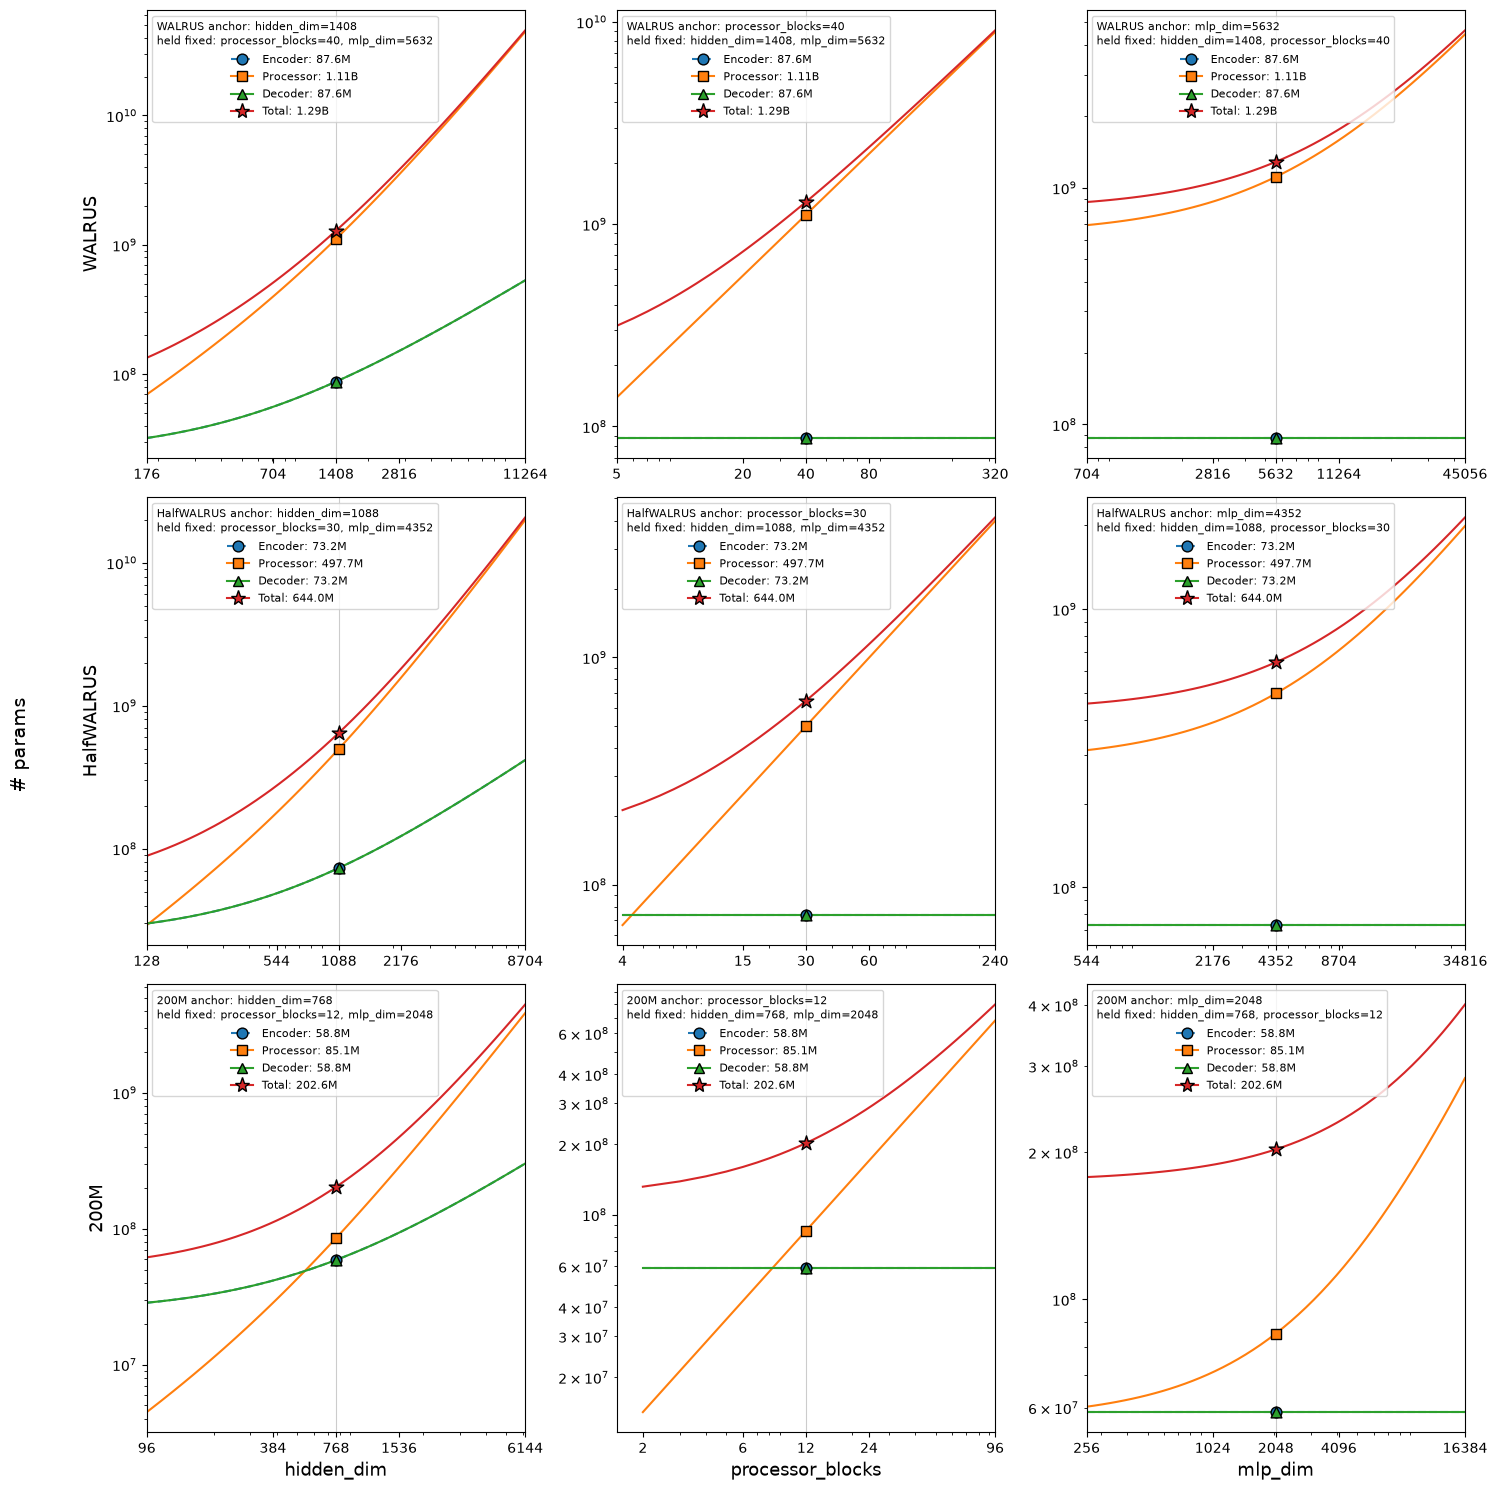

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter

model_dims = {
    "WALRUS":     {"hidden_dim": 1408, "processor_blocks": 40, "mlp_dim": 4 * 1408},
    "HalfWALRUS": {"hidden_dim": 1088, "processor_blocks": 30, "mlp_dim": 4 * 1088},
    "200M":       {"hidden_dim": 768,  "processor_blocks": 12, "mlp_dim": 2048},
}
dim_labels = ["hidden_dim", "processor_blocks", "mlp_dim"]

# Each sweep runs from anchor / SPAN to anchor * SPAN, evenly spaced in log, so the anchor sits
# in the middle of a log-scaled axis.
SPAN = 8
N_POINTS = 51  # odd, so the middle point is the anchor itself
MULTIPLE = {"hidden_dim": 16, "processor_blocks": 1, "mlp_dim": 2}  # heads/groups; int; SwiGLU


def sweep(anchor, multiple):
    x = np.geomspace(anchor / SPAN, anchor * SPAN, N_POINTS)
    x = np.maximum(multiple, (x / multiple).round().astype(int) * multiple)
    return np.unique(x)  # rounding can repeat values at the low end (e.g. small block counts)


def fmt_params(n):
    return f"{n / 1e9:.2f}B" if n >= 1e9 else f"{n / 1e6:.1f}M"


parts = {"encoder": "Encoder", "processor": "Processor", "decoder": "Decoder", "total": "Total"}
markers = {"encoder": "o", "processor": "s", "decoder": "^", "total": "*"}

fig, axs = plt.subplots(ncols=3, nrows=3, figsize=(15, 15))
for ax_row, (model, dims) in zip(axs, model_dims.items()):
    ax_row[0].set_ylabel(model, fontsize=13)
    anchor = walrus_param_count_analytical(**dims)
    for ax, dim in zip(ax_row, dim_labels):
        a = dims[dim]
        xs = sweep(a, MULTIPLE[dim])

        # Vary one dimension; the other two stay at this model's values.
        ys = [walrus_param_count_analytical(**{**dims, dim: x}) for x in xs]
        handles = []
        for key, label in parts.items():
            (line,) = ax.plot(xs, [y[key] for y in ys], ls="--" if key == "encoder" else "-")
            c = line.get_color()
            size = 120 if key == "total" else 60
            ax.scatter(a, anchor[key], color=c, marker=markers[key], s=size, edgecolor="k", zorder=3)
            # One legend entry per part: its line, its anchor marker, and the anchor's count.
            handles.append(Line2D([], [], color=c, ls=line.get_linestyle(), marker=markers[key],
                                  markersize=np.sqrt(size), markeredgecolor="k",
                                  label=f"{label}: {fmt_params(anchor[key])}"))
        ax.set_xscale("log"); ax.set_yscale("log")
        # Symmetric in log about the anchor, so it is centred whatever the rounding did.
        ax.set_xlim(a / SPAN, a * SPAN)
        # A few plain-number ticks (anchor in the middle) instead of crowded log minor labels.
        m = MULTIPLE[dim]
        ticks = sorted({max(m, round(t / m) * m) for t in (a / SPAN, a / 2, a, a * 2, a * SPAN)})
        ax.set_xticks(ticks, [str(t) for t in ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.axvline(a, color="0.8", lw=0.8, zorder=0)
        # Legend title: the anchor value on this axis, and the two dimensions held fixed.
        held = ", ".join(f"{d}={dims[d]}" for d in dim_labels if d != dim)
        ax.legend(handles=handles, fontsize=8, loc="upper left", title_fontsize=8,
                  title=f"{model} anchor: {dim}={a}\nheld fixed: {held}")

for ax, dim in zip(axs[-1], dim_labels):
    ax.set_xlabel(dim, fontsize=13)
fig.supylabel("# params", fontsize=14, x=0.005)

fig.tight_layout(rect=(0.02, 0, 1, 1))  # leave room at the left for the shared y label


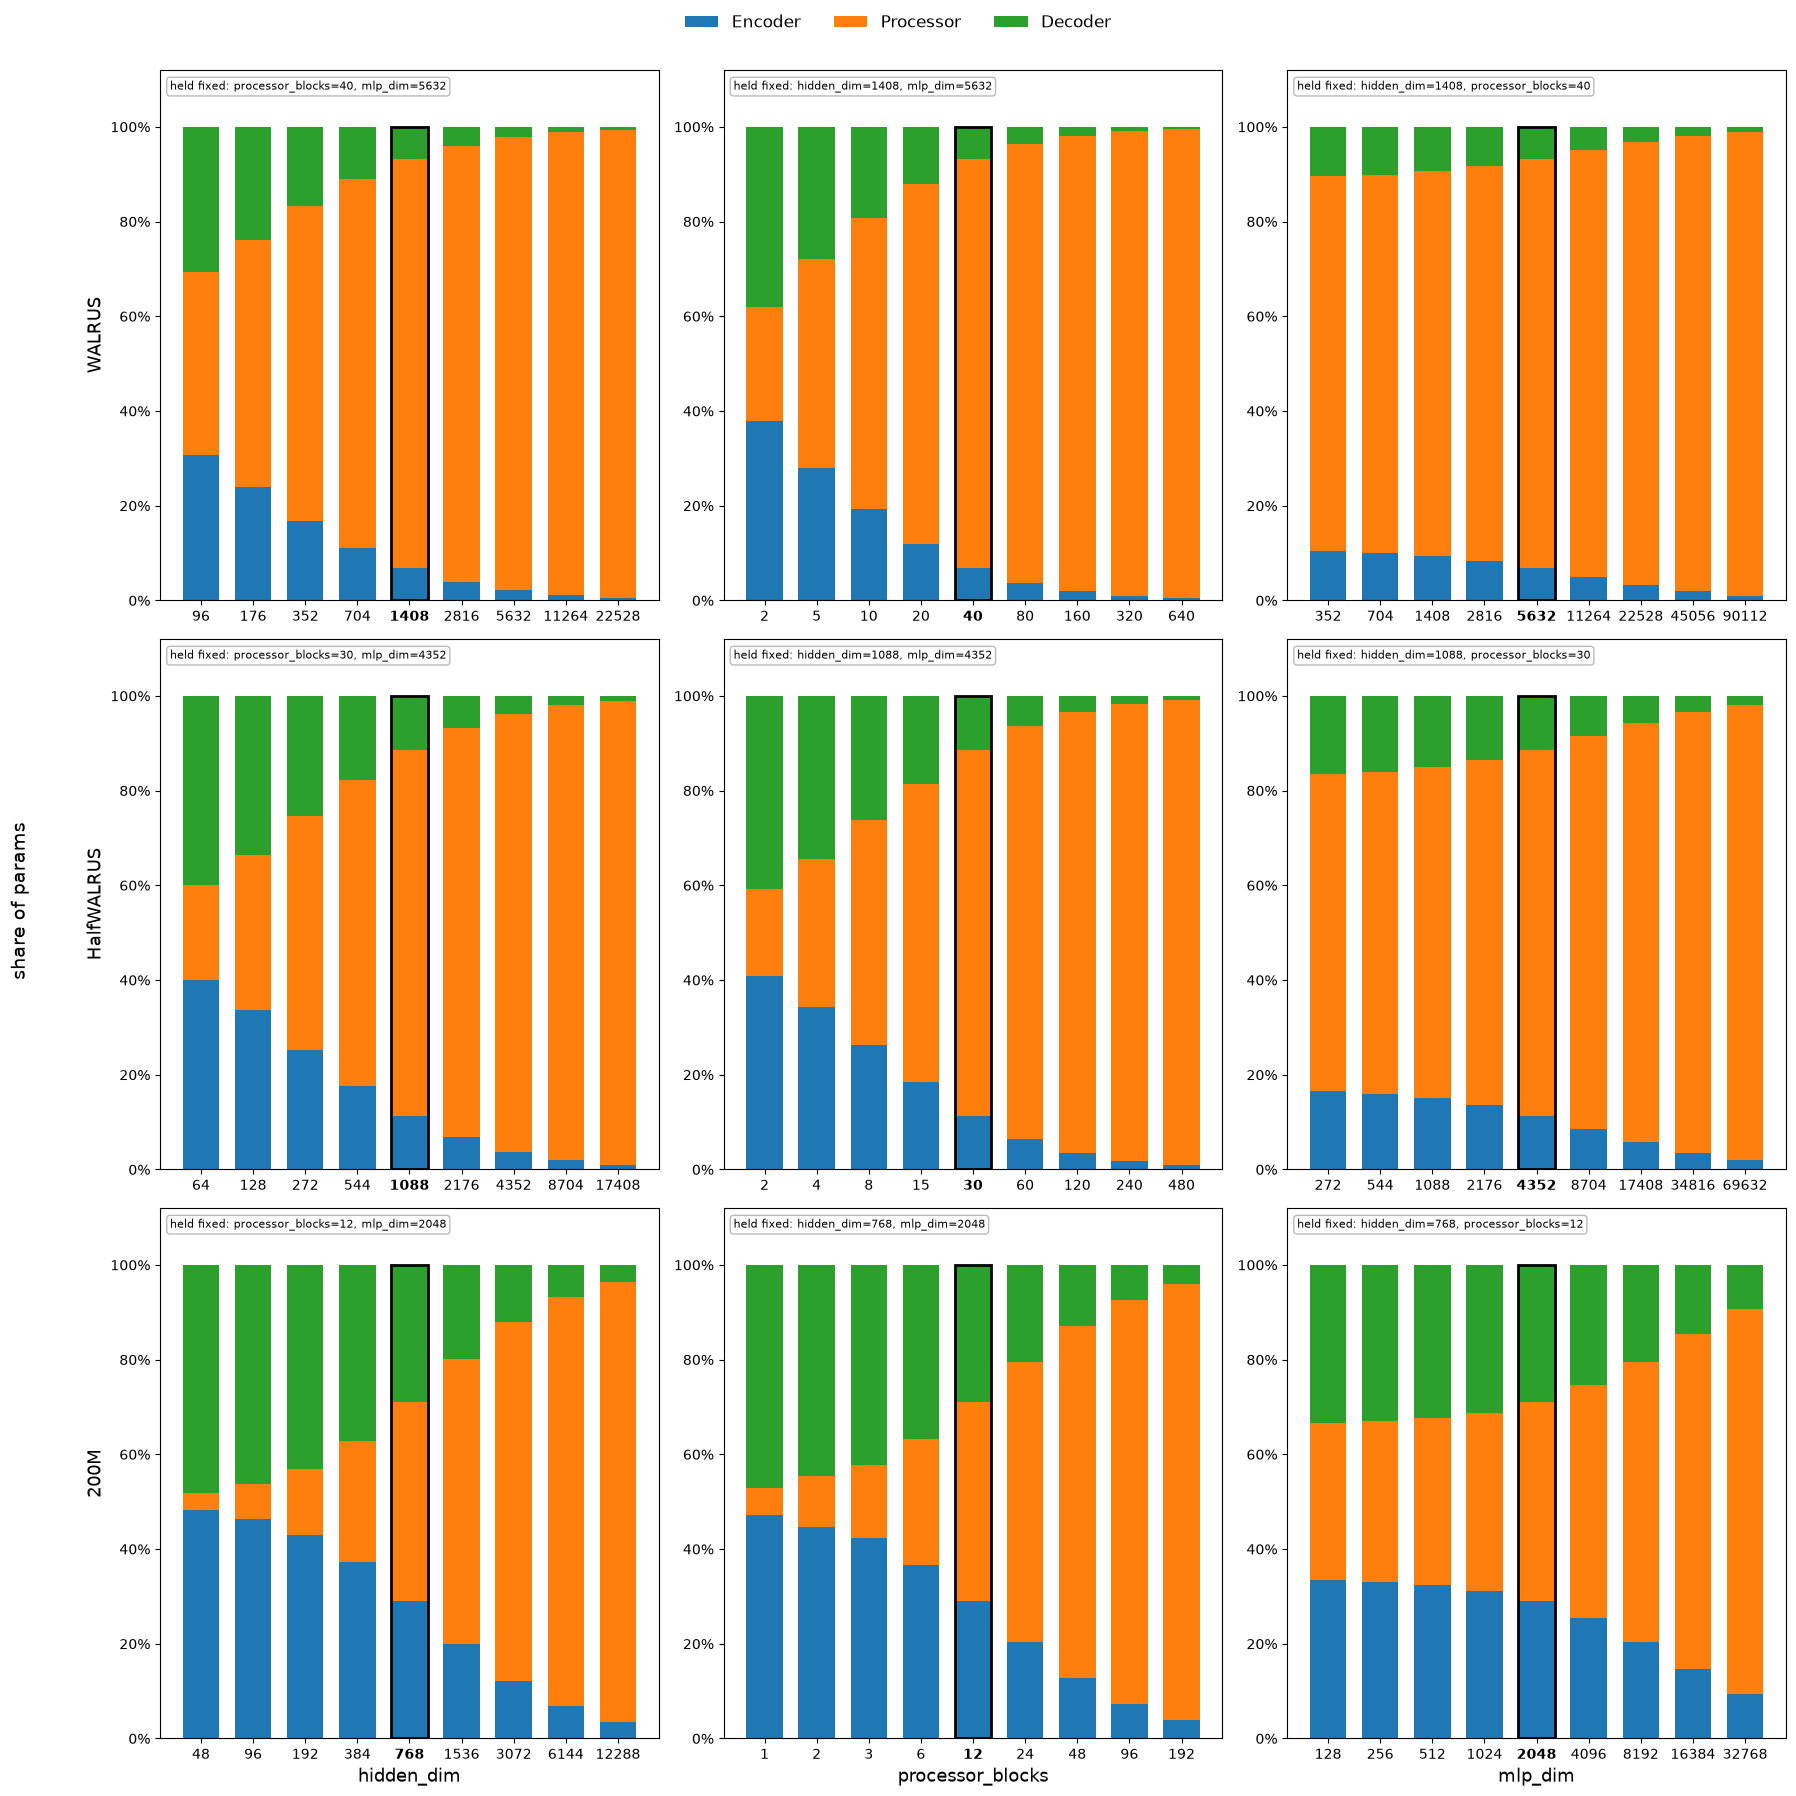

In [9]:
from matplotlib.ticker import FuncFormatter, PercentFormatter

model_dims = {
    "WALRUS":     {"hidden_dim": 1408, "processor_blocks": 40, "mlp_dim": 4 * 1408},
    "HalfWALRUS": {"hidden_dim": 1088, "processor_blocks": 30, "mlp_dim": 4 * 1088},
    "200M":       {"hidden_dim": 768,  "processor_blocks": 12, "mlp_dim": 2048},
}
dim_labels = ["hidden_dim", "processor_blocks", "mlp_dim"]
MULTIPLE = {"hidden_dim": 16, "processor_blocks": 1, "mlp_dim": 2}  # heads/groups; int; SwiGLU

FACTORS = [1 / 16, 1 / 8, 1 / 4, 1 / 2, 1, 2, 4, 8, 16]  # bars at these multiples of the anchor; 1 = the model itself
NORMALISE = True                  # True: plot each part's share of the total instead of counts

parts = {"encoder": "Encoder", "processor": "Processor", "decoder": "Decoder"}
colors = {"encoder": "tab:blue", "processor": "tab:orange", "decoder": "tab:green"}


def fmt_params(n, _=None):
    return f"{n / 1e9:.1f}B" if n >= 1e9 else f"{n / 1e6:.0f}M"


fig, axs = plt.subplots(ncols=3, nrows=3, figsize=(18, 18))
for ax_row, (model, dims) in zip(axs, model_dims.items()):
    ax_row[0].set_ylabel(model, fontsize=13)
    for ax, dim in zip(ax_row, dim_labels):
        a, m = dims[dim], MULTIPLE[dim]
        values = [max(m, round(a * f / m) * m) for f in FACTORS]  # valid values only
        # Vary one dimension; the other two stay at this model's values.
        counts = [walrus_param_count_analytical(**{**dims, dim: v}) for v in values]

        x = np.arange(len(values))
        bottom = np.zeros(len(values))
        for key, label in parts.items():
            h = np.array([c[key] for c in counts], dtype=float)
            if NORMALISE:
                h /= np.array([c["encoder"] + c["processor"] + c["decoder"] for c in counts])
            ax.bar(x, h, bottom=bottom, color=colors[key], label=label, width=0.7)
            bottom += h
        # Outline the anchor bar (the model itself) and bold its tick label.
        i = values.index(a)
        ax.bar(x[i], bottom[i], width=0.7, fill=False, edgecolor="k", lw=2)

        ax.set_ylim(0, bottom.max() * 1.12)  # headroom so the note never covers a bar
        ax.set_xticks(x, [str(v) for v in values])
        ax.get_xticklabels()[i].set_fontweight("bold")
        ax.yaxis.set_major_formatter(PercentFormatter(1.0) if NORMALISE else FuncFormatter(fmt_params))
        held = ", ".join(f"{d}={dims[d]}" for d in dim_labels if d != dim)
        ax.text(0.02, 0.98, f"held fixed: {held}", transform=ax.transAxes,
                ha="left", va="top", fontsize=8,
                bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))

for ax, dim in zip(axs[-1], dim_labels):
    ax.set_xlabel(dim, fontsize=13)
fig.supylabel("share of params" if NORMALISE else "# params", fontsize=14, x=0.005)
# One legend for the whole figure (the parts are the same in every panel).
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, fontsize=12, frameon=False)

fig.tight_layout(rect=(0.02, 0, 1, 0.97))  # room for the shared y label and the legend


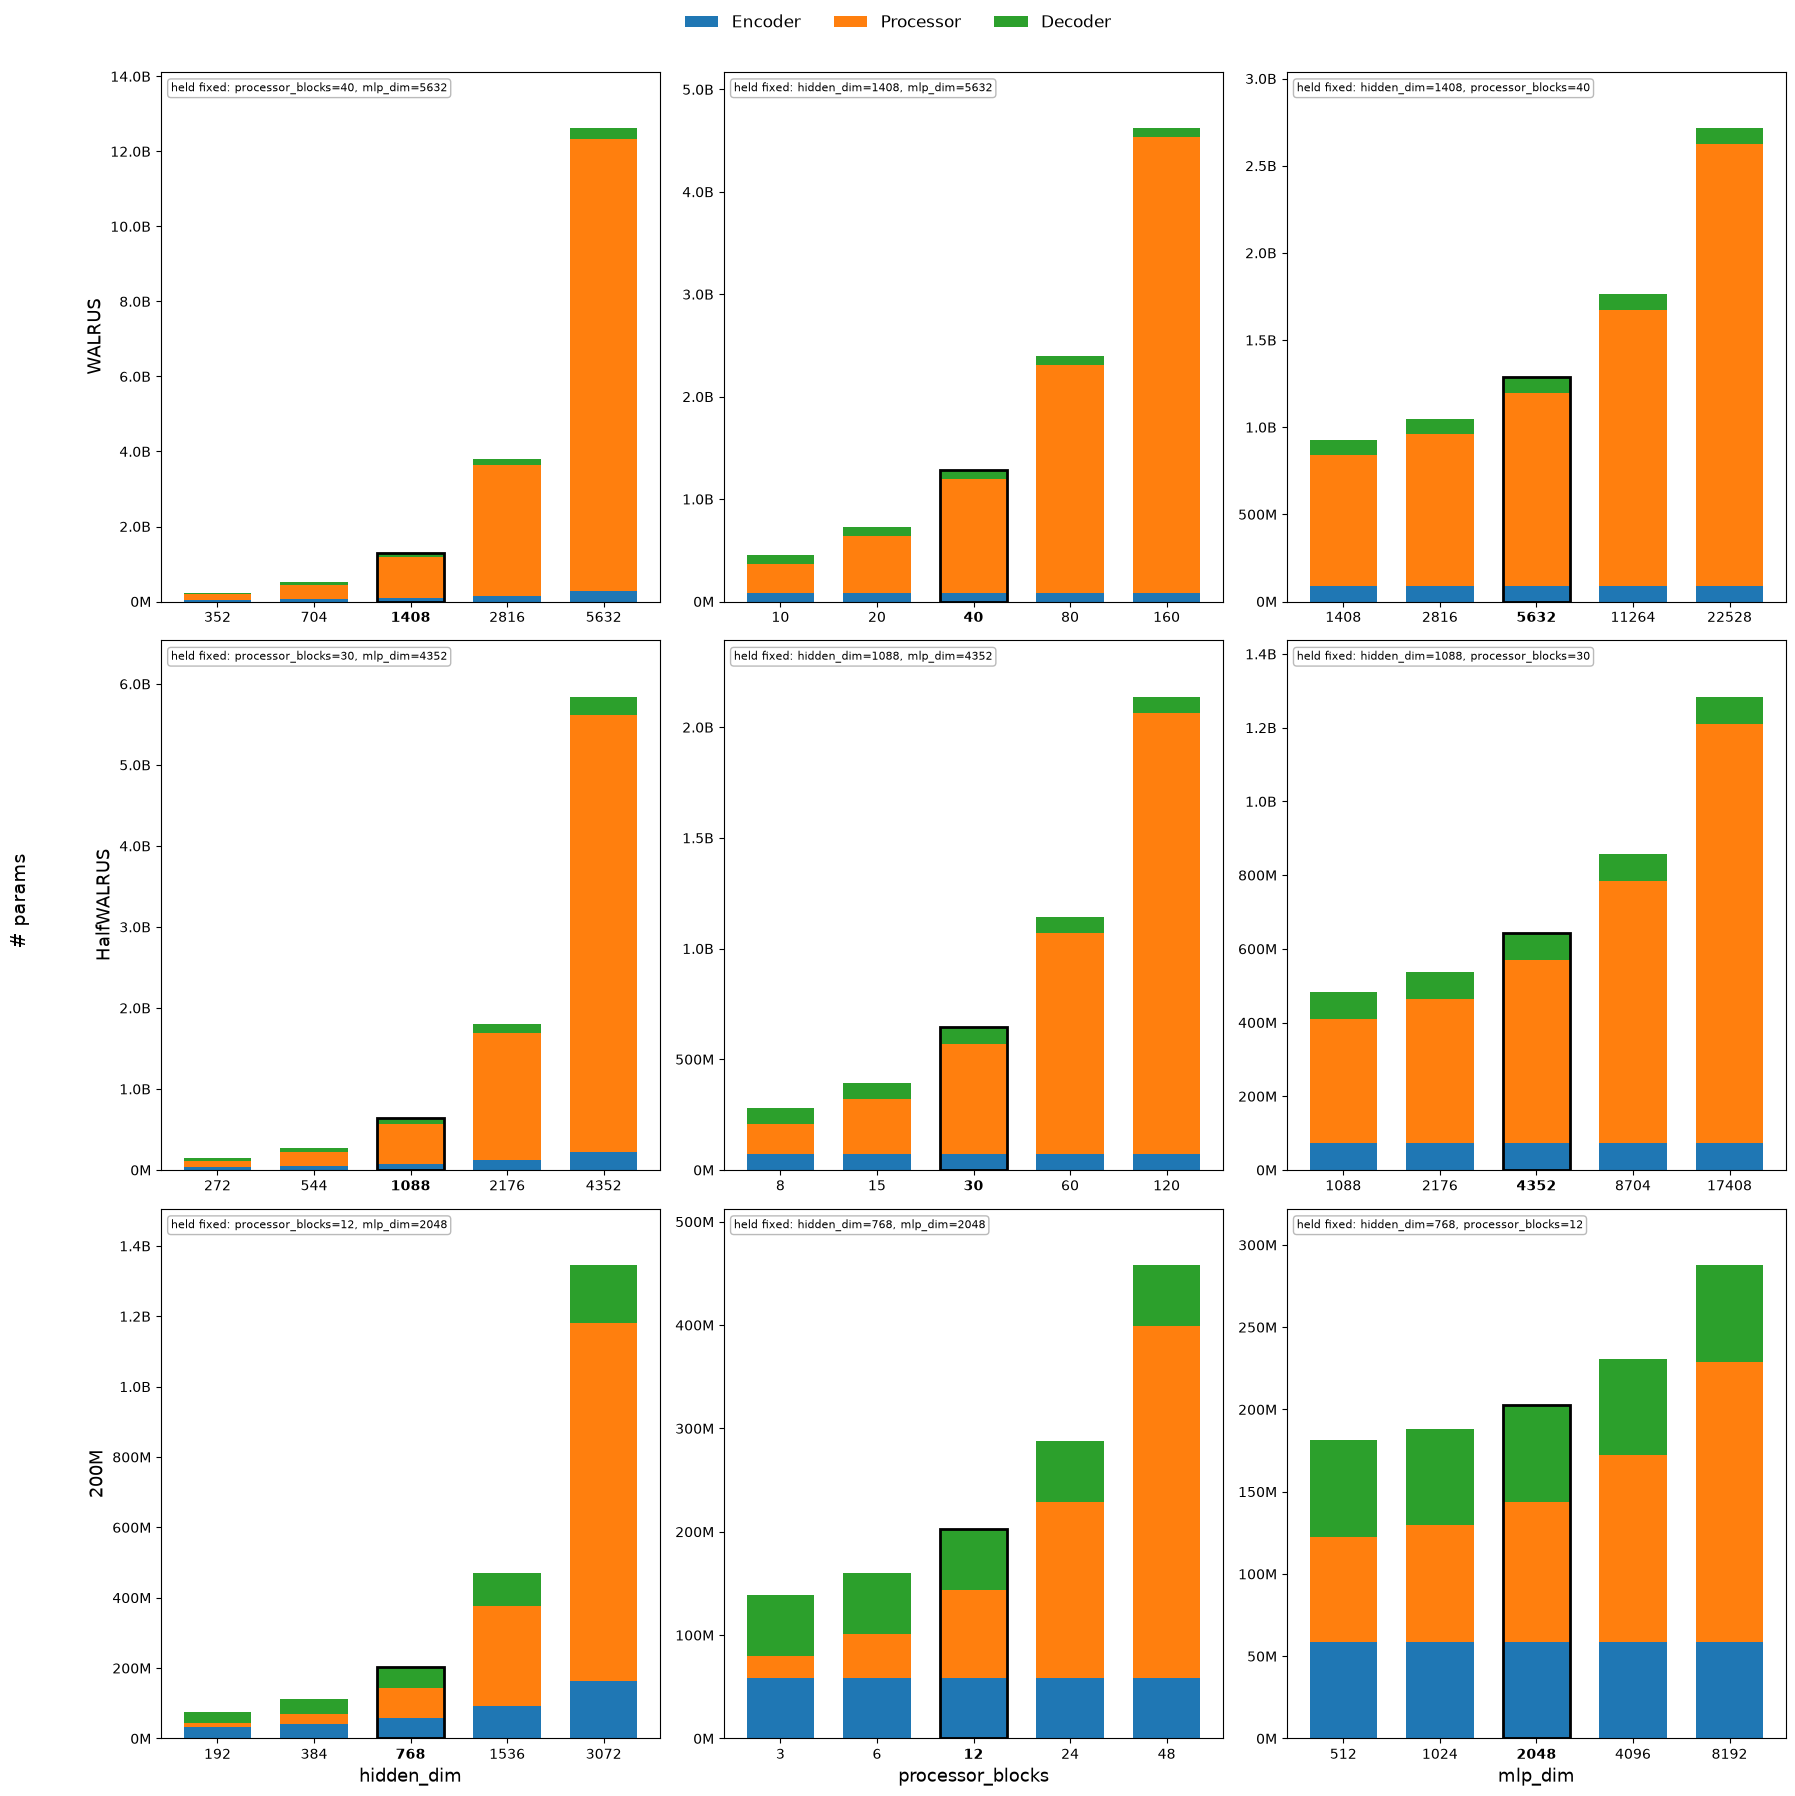

In [10]:
model_dims = {
    "WALRUS":     {"hidden_dim": 1408, "processor_blocks": 40, "mlp_dim": 4 * 1408},
    "HalfWALRUS": {"hidden_dim": 1088, "processor_blocks": 30, "mlp_dim": 4 * 1088},
    "200M":       {"hidden_dim": 768,  "processor_blocks": 12, "mlp_dim": 2048},
}
dim_labels = ["hidden_dim", "processor_blocks", "mlp_dim"]
MULTIPLE = {"hidden_dim": 16, "processor_blocks": 1, "mlp_dim": 2}  # heads/groups; int; SwiGLU

FACTORS = [1 / 4, 1 / 2, 1, 2, 4]  # bars at these multiples of the anchor; 1 = the model itself
NORMALISE = False                  # True: plot each part's share of the total instead of counts

parts = {"encoder": "Encoder", "processor": "Processor", "decoder": "Decoder"}
colors = {"encoder": "tab:blue", "processor": "tab:orange", "decoder": "tab:green"}


def fmt_params(n, _=None):
    return f"{n / 1e9:.1f}B" if n >= 1e9 else f"{n / 1e6:.0f}M"


fig, axs = plt.subplots(ncols=3, nrows=3, figsize=(18, 18))
for ax_row, (model, dims) in zip(axs, model_dims.items()):
    ax_row[0].set_ylabel(model, fontsize=13)
    for ax, dim in zip(ax_row, dim_labels):
        a, m = dims[dim], MULTIPLE[dim]
        values = [max(m, round(a * f / m) * m) for f in FACTORS]  # valid values only
        # Vary one dimension; the other two stay at this model's values.
        counts = [walrus_param_count_analytical(**{**dims, dim: v}) for v in values]

        x = np.arange(len(values))
        bottom = np.zeros(len(values))
        for key, label in parts.items():
            h = np.array([c[key] for c in counts], dtype=float)
            if NORMALISE:
                h /= np.array([c["encoder"] + c["processor"] + c["decoder"] for c in counts])
            ax.bar(x, h, bottom=bottom, color=colors[key], label=label, width=0.7)
            bottom += h
        # Outline the anchor bar (the model itself) and bold its tick label.
        i = values.index(a)
        ax.bar(x[i], bottom[i], width=0.7, fill=False, edgecolor="k", lw=2)

        ax.set_ylim(0, bottom.max() * 1.12)  # headroom so the note never covers a bar
        ax.set_xticks(x, [str(v) for v in values])
        ax.get_xticklabels()[i].set_fontweight("bold")
        ax.yaxis.set_major_formatter(PercentFormatter(1.0) if NORMALISE else FuncFormatter(fmt_params))
        held = ", ".join(f"{d}={dims[d]}" for d in dim_labels if d != dim)
        ax.text(0.02, 0.98, f"held fixed: {held}", transform=ax.transAxes,
                ha="left", va="top", fontsize=8,
                bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))

for ax, dim in zip(axs[-1], dim_labels):
    ax.set_xlabel(dim, fontsize=13)
fig.supylabel("share of params" if NORMALISE else "# params", fontsize=14, x=0.005)
# One legend for the whole figure (the parts are the same in every panel).
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, fontsize=12, frameon=False)

fig.tight_layout(rect=(0.02, 0, 1, 0.97))  # room for the shared y label and the legend

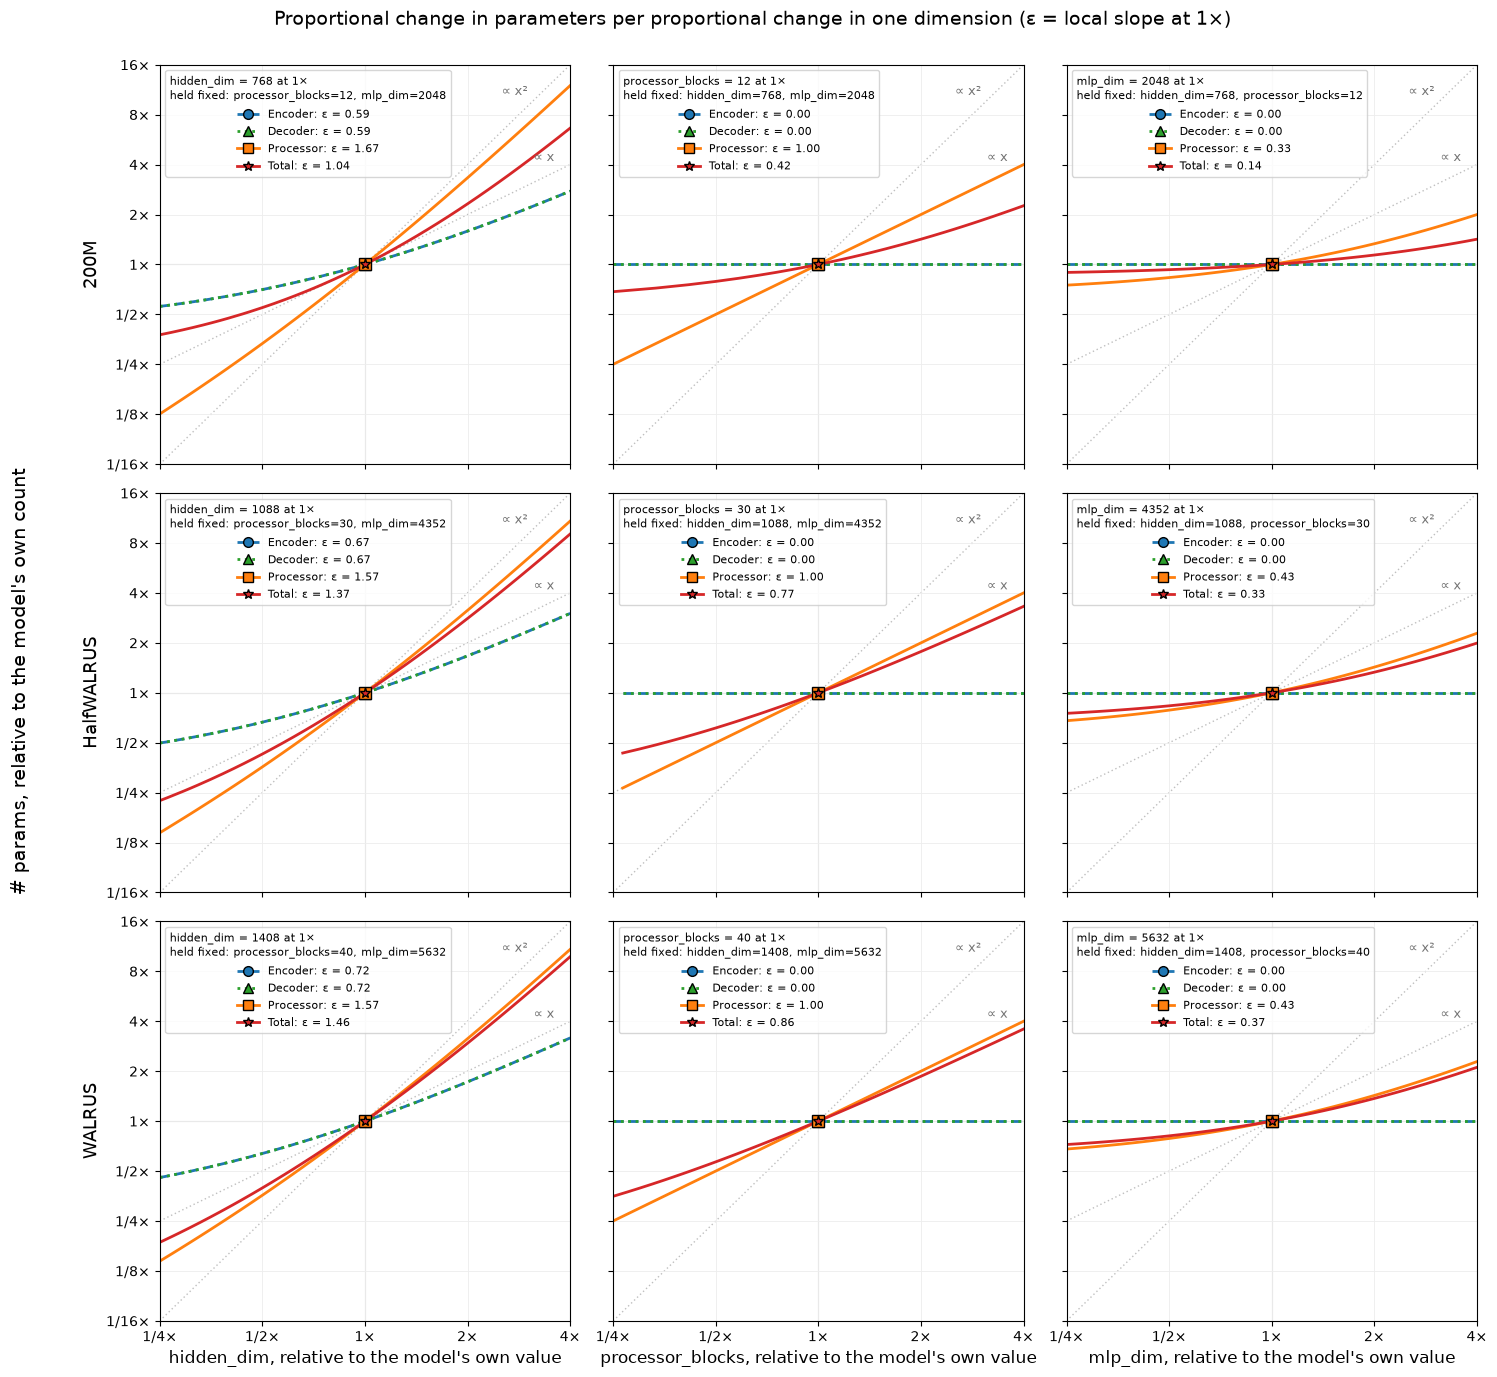

In [11]:
# from matplotlib.ticker import FuncFormatter, NullFormatter

model_dims = {
    "200M":       {"hidden_dim": 768,  "processor_blocks": 12, "mlp_dim": 2048},
    "HalfWALRUS": {"hidden_dim": 1088, "processor_blocks": 30, "mlp_dim": 4 * 1088},
    "WALRUS":     {"hidden_dim": 1408, "processor_blocks": 40, "mlp_dim": 4 * 1408},
}
dim_labels = ["hidden_dim", "processor_blocks", "mlp_dim"]
MULTIPLE = {"hidden_dim": 16, "processor_blocks": 1, "mlp_dim": 2}  # heads/groups; int; SwiGLU

SPAN = 4        # each dimension is scaled from 1/SPAN to SPAN times the model's own value
N_POINTS = 41

# Same colour per part as the earlier plots; line style + marker as well, so encoder and
# decoder (which nearly coincide) and the colour-blind-confusable green/red stay distinguishable.
parts = {
    "encoder":   dict(label="Encoder",   color="tab:blue",   ls="--", marker="o"),
    "decoder":   dict(label="Decoder",   color="tab:green",  ls=":",  marker="^"),
    "processor": dict(label="Processor", color="tab:orange", ls="-",  marker="s"),
    "total":     dict(label="Total",     color="tab:red",    ls="-",  marker="*"),
}


def valid(values, m):
    """Round to the nearest valid value of this dimension (multiple of m, at least m)."""
    return np.unique(np.maximum(m, np.round(np.asarray(values) / m).astype(int) * m))


def elasticity(dims, dim, key):
    """Local d ln N / d ln x at the model itself: the % change in N per 1 % change in `dim`.

    Central difference over the smallest valid step either side (exact for the processor
    vs processor_blocks, which is linear; a close approximation elsewhere).
    """
    x, m = dims[dim], MULTIPLE[dim]
    lo = walrus_param_count_analytical(**{**dims, dim: x - m})[key]
    hi = walrus_param_count_analytical(**{**dims, dim: x + m})[key]
    return np.log(hi / lo) / np.log((x + m) / (x - m))


fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(15, 14), sharex=True, sharey=True)
ref_x = np.array([1 / SPAN, SPAN])
for ax_row, (model, dims) in zip(axs, model_dims.items()):
    ax_row[0].set_ylabel(model, fontsize=13)
    base = walrus_param_count_analytical(**dims)
    for ax, dim in zip(ax_row, dim_labels):
        x0 = dims[dim]
        xs = valid(np.geomspace(x0 / SPAN, x0 * SPAN, N_POINTS), MULTIPLE[dim])
        counts = [walrus_param_count_analytical(**{**dims, dim: x}) for x in xs]

        # Reference slopes: N proportional to x (linear) and to x^2 (quadratic).
        for p, txt, xl in ((1, "∝ x", 3.6), (2, "∝ x²", 3.0)):
            ax.plot(ref_x, ref_x ** p, color="0.75", lw=1, ls=(0, (1, 2)), zorder=0)
            ax.text(xl, xl ** p * 1.12, txt, color="0.45", fontsize=9, ha="right", va="bottom")
        ax.axhline(1, color="0.85", lw=0.8, zorder=0)
        ax.axvline(1, color="0.85", lw=0.8, zorder=0)

        handles = []
        for key, st in parts.items():
            ratio = np.array([c[key] for c in counts]) / base[key]
            ax.plot(xs / x0, ratio, color=st["color"], ls=st["ls"], lw=2)
            ax.plot(1, 1, color=st["color"], marker=st["marker"], ms=8, mec="k", zorder=3)
            eps = elasticity(dims, dim, key)
            handles.append(Line2D([], [], color=st["color"], ls=st["ls"], lw=2, marker=st["marker"],
                                  ms=7, mec="k", label=f"{st['label']}: ε = {eps:.2f}"))
        held = ", ".join(f"{d}={dims[d]}" for d in dim_labels if d != dim)
        ax.legend(handles=handles, fontsize=8, loc="upper left", title_fontsize=8,
                  title=f"{dim} = {x0} at 1×\nheld fixed: {held}")

for ax in axs.flat:
    ax.set_xscale("log", base=2)
    ax.set_yscale("log", base=2)
    ax.set_xlim(1 / SPAN, SPAN)
    ax.set_ylim(1 / SPAN ** 2, SPAN ** 2)
    ax.grid(True, which="major", color="0.93", lw=0.6)
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.yaxis.set_minor_formatter(NullFormatter())
ratio_fmt = FuncFormatter(lambda v, _: f"{v:g}×" if v >= 1 else f"1/{1 / v:g}×")
axs[0, 0].xaxis.set_major_formatter(ratio_fmt)   # shared axes: sets every panel
axs[0, 0].yaxis.set_major_formatter(ratio_fmt)
for ax, dim in zip(axs[-1], dim_labels):
    ax.set_xlabel(f"{dim}, relative to the model's own value", fontsize=12)
fig.supylabel("# params, relative to the model's own count", fontsize=14, x=0.005)
fig.suptitle("Proportional change in parameters per proportional change in one dimension "
             "(ε = local slope at 1×)", fontsize=14)
fig.tight_layout(rect=(0.02, 0, 1, 0.98))
